# F4: herding, capital concentration and market-maker sensitivity

Single-asset experiment, 30 sessions, 5-session warmup, snapshots every 0.02 session.
80 investors and one finite-resource market maker. Pilot seeds 1–3; main seeds 1001–1030.
The protocol was frozen in `docs/guides/f4_simulation.md` before the main runs.
This notebook reads only K3 logs and CSV diagnostics; it does not import the simulation engine.
The sampling horizon is short: results are exploratory and do not establish market realism.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

from marketsim.sim.log_schema import load_run

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / "runs" / "f4"
frames = {name: pd.read_csv(RESULTS / name / "summary.csv") for name in ("pilot", "e1", "e2", "e3")}
print("Run counts:", {name: len(frame) for name, frame in frames.items()})
assert {name: len(frame) for name, frame in frames.items()} == {"pilot": 3, "e1": 270, "e2": 90, "e3": 90}


Run counts: {'pilot': 3, 'e1': 270, 'e2': 90, 'e3': 90}


## Diagnostic definitions

`max_drawdown` and `relative_valuation_error` use two-sided midpoint snapshots.
`empty_side_fraction` weights missing-side snapshots by the interval they represent.
`execution_rate` uses eventual fills of orders submitted after warmup.
These are F4 pilot diagnostics; formal validation and shared research metrics belong to D1.
Each independent seed is one statistical unit. The same main seeds allow paired contrasts.


In [2]:
metrics = ["max_drawdown", "empty_side_fraction", "relative_valuation_error", "execution_rate"]
print("Pilot diagnostics:")
print(frames["pilot"][["seed", "wall_time_s", "trade_count"] + metrics].to_string(index=False))
print("\nE1 medians by herding and concentration:")
print(frames["e1"].groupby(["agents.herding.h", "agents.concentration"])[metrics].median().to_string())
print("\nE2 medians by ablation:")
print(frames["e2"].groupby("agents.ablation")[metrics].median().to_string())
print("\nE3 medians by maker spread (ticks):")
print(frames["e3"].groupby("agents.market_maker_spread_ticks")[metrics].median().to_string())


Pilot diagnostics:
 seed  wall_time_s  trade_count  max_drawdown  empty_side_fraction  relative_valuation_error  execution_rate
    1     0.141309          662      0.004609               0.0016                  0.002739        0.142147
    2     0.153325         1082      0.015062               0.0072                  0.014954        0.160720
    3     0.197995          717      0.001847               0.0024                  0.001867        0.108910

E1 medians by herding and concentration:
                                       max_drawdown  empty_side_fraction  relative_valuation_error  execution_rate
agents.herding.h agents.concentration                                                                             
0.0              0.2                       0.001642               0.0000                  0.001372        0.126602
                 0.5                       0.005087               0.0024                  0.004955        0.126950
                 0.8                       

In [3]:
def paired_bootstrap(treatment, control, metric, seed):
    pairs = treatment[["seed", metric]].merge(control[["seed", metric]], on="seed", suffixes=("_t", "_c"))
    differences = pairs[f"{metric}_t"].to_numpy() - pairs[f"{metric}_c"].to_numpy()
    rng = np.random.default_rng(seed)
    means = rng.choice(differences, size=(10000, len(differences)), replace=True).mean(axis=1)
    low, high = np.quantile(means, [0.025, 0.975])
    return {"mean_difference": differences.mean(), "ci_low": low, "ci_high": high, "paired_runs": len(pairs)}

contrasts = []
e1 = frames["e1"]
for concentration in (0.2, 0.5, 0.8):
    control = e1.query("`agents.herding.h` == 0.0 and `agents.concentration` == @concentration")
    treatment = e1.query("`agents.herding.h` == 0.6 and `agents.concentration` == @concentration")
    for metric in ("max_drawdown", "empty_side_fraction"):
        contrasts.append({"contrast": "h=0.6 minus h=0", "C": concentration, "metric": metric,
                          **paired_bootstrap(treatment, control, metric, 20261029)})
print(pd.DataFrame(contrasts).to_string(index=False))


       contrast   C              metric  mean_difference   ci_low  ci_high  paired_runs
h=0.6 minus h=0 0.2        max_drawdown         0.120533 0.105531 0.135739           30
h=0.6 minus h=0 0.2 empty_side_fraction         0.050080 0.044907 0.055227           30
h=0.6 minus h=0 0.5        max_drawdown         0.106250 0.092127 0.120376           30
h=0.6 minus h=0 0.5 empty_side_fraction         0.067600 0.060853 0.074667           30
h=0.6 minus h=0 0.8        max_drawdown         0.084083 0.058810 0.110256           30
h=0.6 minus h=0 0.8 empty_side_fraction         0.078533 0.065733 0.091067           30


In [4]:
print("Representative E1 runs selected by drawdown, never by visual appearance:")
selected = []
for keys, group in e1.groupby(["agents.herding.h", "agents.concentration"]):
    for quantile in (0.5, 0.9):
        target = group.max_drawdown.quantile(quantile)
        row = group.loc[(group.max_drawdown - target).abs().idxmin()]
        log = load_run(RESULTS / "e1" / row.run_id)
        assert log.meta["initial_resources"] == log.meta["final_resources"]
        selected.append({"h": keys[0], "C": keys[1], "quantile": quantile,
                         "seed": int(row.seed), "run_id": row.run_id, "max_drawdown": row.max_drawdown})
print(pd.DataFrame(selected).to_string(index=False))


Representative E1 runs selected by drawdown, never by visual appearance:
  h   C  quantile  seed                  run_id  max_drawdown
0.0 0.2       0.5  1010 f4_1d4a53da3f01e043cdf2      0.001539
0.0 0.2       0.9  1018 f4_3c68ad87f15c96e95abc      0.004377
0.0 0.5       0.5  1012 f4_904e0573c3267b52ffdc      0.005258
0.0 0.5       0.9  1026 f4_48544d8012d14dbd293a      0.009111
0.0 0.8       0.5  1006 f4_c3784e9808b6d32943f5      0.014739
0.0 0.8       0.9  1019 f4_412faa4a1dfaf8e4ebfe      0.059893
0.3 0.2       0.5  1010 f4_93ee2074e37eb8894604      0.004727
0.3 0.2       0.9  1019 f4_016a4b280a81458fc4b7      0.008949
0.3 0.5       0.5  1006 f4_b83560b7d638b5d0f9ae      0.010562
0.3 0.5       0.9  1015 f4_53c9cfb6974467a9bb74      0.020915
0.3 0.8       0.5  1003 f4_d55ce5a7f27350ab578c      0.020520
0.3 0.8       0.9  1015 f4_2b458212cbdf897b9a7a      0.058317
0.6 0.2       0.5  1018 f4_eca3178c45f36cd7279e      0.120563
0.6 0.2       0.9  1028 f4_889d8a9c1f46948aafa0      0.1723

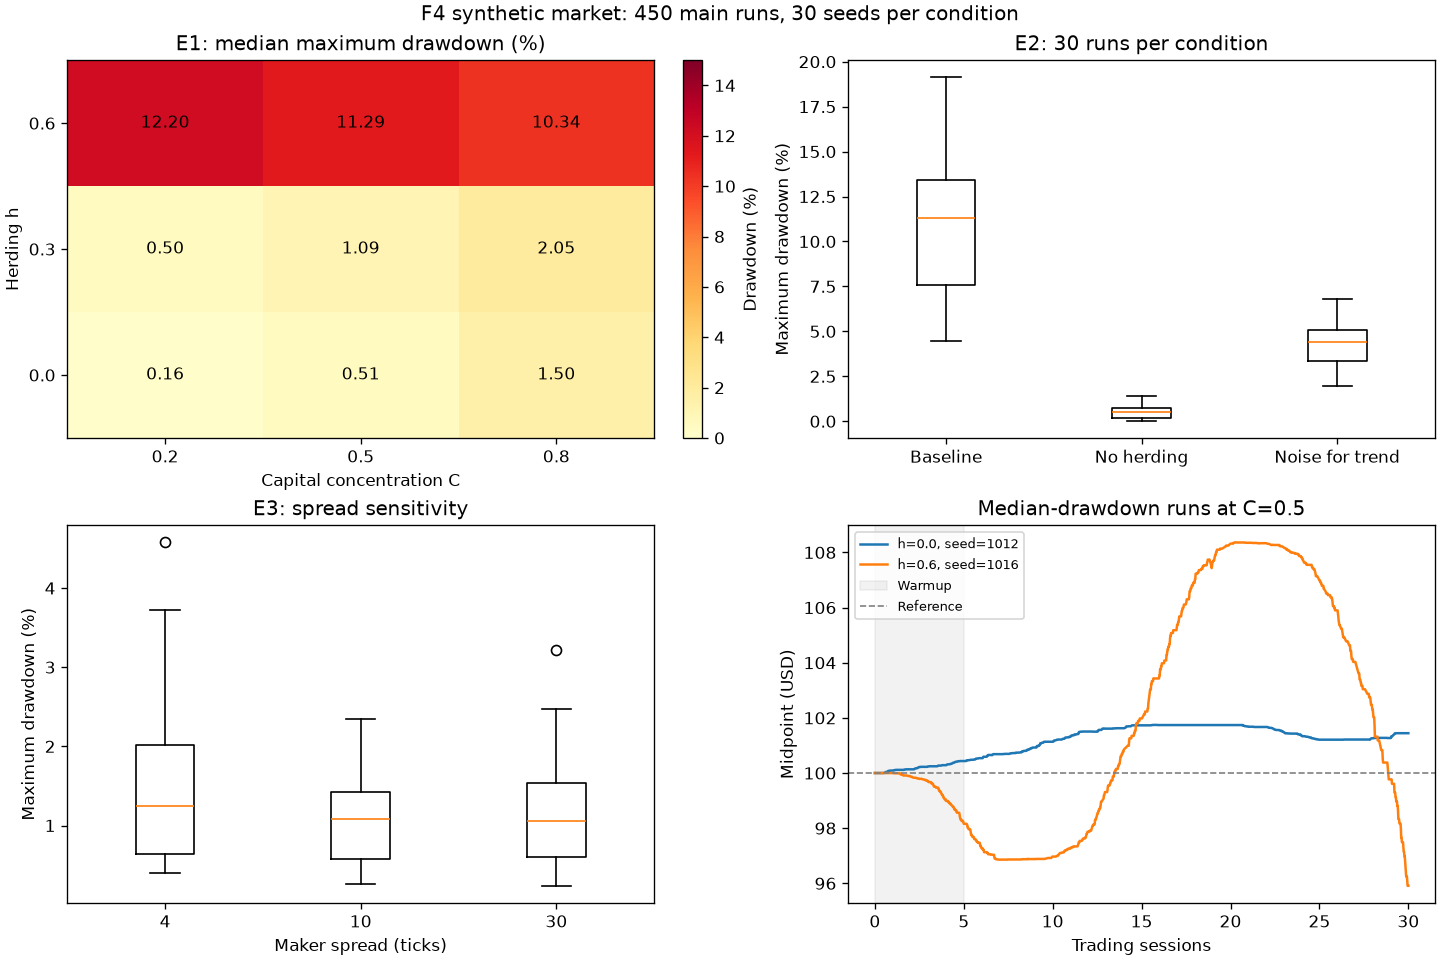

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
heat = e1.pivot_table(index="agents.herding.h", columns="agents.concentration", values="max_drawdown", aggfunc="median")
image = axes[0, 0].imshow(100 * heat.to_numpy(), origin="lower", aspect="auto", cmap="YlOrRd", vmin=0, vmax=15)
axes[0, 0].set(xticks=range(3), xticklabels=heat.columns, yticks=range(3), yticklabels=heat.index,
               xlabel="Capital concentration C", ylabel="Herding h", title="E1: median maximum drawdown (%)")
for i in range(3):
    for j in range(3):
        axes[0, 0].text(j, i, f"{100 * heat.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=axes[0, 0], label="Drawdown (%)")

labels = ["none", "no_herding", "no_trend"]
axes[0, 1].boxplot([100 * frames["e2"].loc[frames["e2"]["agents.ablation"] == k, "max_drawdown"] for k in labels],
                   tick_labels=["Baseline", "No herding", "Noise for trend"])
axes[0, 1].set(ylabel="Maximum drawdown (%)", title="E2: 30 runs per condition")
axes[0, 1].tick_params(axis="x", labelrotation=0)

spreads = [4, 10, 30]
axes[1, 0].boxplot([100 * frames["e3"].loc[frames["e3"]["agents.market_maker_spread_ticks"] == k, "max_drawdown"]
                   for k in spreads], tick_labels=spreads)
axes[1, 0].set(xlabel="Maker spread (ticks)", ylabel="Maximum drawdown (%)", title="E3: spread sensitivity")

for h in (0.0, 0.6):
    group = e1.query("`agents.herding.h` == @h and `agents.concentration` == 0.5")
    row = group.loc[(group.max_drawdown - group.max_drawdown.median()).abs().idxmin()]
    log = load_run(RESULTS / "e1" / row.run_id)
    book = log["book"]
    valid = (book.best_bid > 0) & (book.best_ask > 0)
    axes[1, 1].plot(book.loc[valid, "t"], (book.loc[valid, "best_bid"] + book.loc[valid, "best_ask"]) / 200,
                    label=f"h={h}, seed={int(row.seed)}")
axes[1, 1].axvspan(0, 5, alpha=0.1, color="gray", label="Warmup")
axes[1, 1].axhline(100, color="gray", linestyle="--", linewidth=1, label="Reference")
axes[1, 1].set(xlabel="Trading sessions", ylabel="Midpoint (USD)", title="Median-drawdown runs at C=0.5")
axes[1, 1].legend(fontsize=8)
fig.suptitle("F4 synthetic market: 450 main runs, 30 seeds per condition")
fig.savefig(RESULTS / "f4_overview.png", dpi=150)
fig.savefig(RESULTS / "f4_overview.svg")
plt.show()


## First findings

At C=0.5, median maximum drawdown is 0.51% at h=0 and 11.29% at h=0.6.
The paired mean difference is 10.62 percentage points (95% bootstrap interval: 9.21–12.04).
Replacing trend signals with noise at h=0.6 lowers median drawdown to 4.43%;
turning herding off lowers it to 0.51%. The large movement therefore depends on both mechanisms
within this parameter range. Concentration effects depend on h; a single monotonic conclusion
across all conditions is not supported. Changing the maker spread from 4 to 30 ticks
has a smaller observed effect than raising h from 0 to 0.6.


## Interpretation limits

The asset dependency graph and historical stock paths are not used in F4.
Funds are a fixed investor subgroup with a different allocation of the same aggregate resources.
In the no-trend ablation, trend agents keep their IDs, resources and wake rates but use noise signals.
The order-status enum lacks manual cancellation and GTD expiry: terminal lifecycle states must be read
from the events table together with orders. See the F4 guide before consuming order status.
A confidence interval spanning zero is reported as an inconclusive contrast. Results apply only to this
parameter range and horizon; longer runs and D1's metrics are needed for broader conclusions.
